In [1]:
# Point-Biserial Correlation for numerical features against the binary target.
# Cramér's V for categorical features against the binary target.



# The difference
# Technique	                          What it detects
# Pearson correlation	               Linear relationships
# Point-Biserial            	Linear numerical-to-binary relationships
# Mutual Information	     Linear and nonlinear statistical dependencies

# MI detects statistical dependence, but does not establish causation.

In [6]:
from scipy.stats import pointbiserialr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_cleaned.csv")

X = df.drop(columns = ["id","dataset","num"])
y = df["num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_features:
    X_train[col] = X_train[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

In [10]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):

    confusion_matrix = pd.crosstab(x, y)

    chi2 = chi2_contingency(
        confusion_matrix,
        correction=False
    )[0]

    n = confusion_matrix.sum().sum()

    if n <= 1:
        return np.nan

    r, k = confusion_matrix.shape

    phi2 = chi2 / n

    # Bias correction
    phi2_corrected = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(
        k_corrected - 1,
        r_corrected - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2_corrected / denominator)

In [8]:
# Numerical features
numerical_features = X_train.select_dtypes(
    include=np.number
).columns

point_biserial_results = []

for col in numerical_features:

    correlation, p_value = pointbiserialr(
        y_train,
        X_train[col]
    )

    point_biserial_results.append({
        "Feature": col,
        "Correlation": correlation,
        "P-value": p_value
    })

point_biserial_df = pd.DataFrame(
    point_biserial_results
)

point_biserial_df = point_biserial_df.sort_values(
    by="Correlation",
    key=abs,
    ascending=False
)

print(point_biserial_df.round(4))

    Feature  Correlation  P-value
0       age       0.3096      0.0
1  trestbps          NaN      NaN
2      chol          NaN      NaN
3    thalch          NaN      NaN
4   oldpeak          NaN      NaN
5        ca          NaN      NaN


In [12]:
categorical_target_results = []

for col in categorical_features:

    association = cramers_v(
        X_train[col].fillna("__MISSING__").astype(str),
        y_train.astype(str)
    )

    categorical_target_results.append({
        "Feature": col,
        "Cramers V": association
    })

categorical_target_df = pd.DataFrame(
    categorical_target_results
)

categorical_target_df = categorical_target_df.sort_values(
    by="Cramers V",
    ascending=False
)

print(categorical_target_df.round(4))

   Feature  Cramers V
1       cp     0.5133
4    exang     0.4478
5    slope     0.3796
6     thal     0.3365
0      sex     0.3029
2      fbs     0.2306
3  restecg     0.1119


In [18]:
from scipy.stats import pointbiserialr

# Identify numerical features again
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical features:", numerical_features)

point_biserial_results = []

for col in numerical_features:

    # Handle missing values while preserving row alignment
    valid = X_train[col].notna() & y_train.notna()

    correlation, p_value = pointbiserialr(
        y_train[valid],
        X_train.loc[valid, col]
    )

    point_biserial_results.append({
        "Feature": col,
        "Correlation": correlation,
        "P-value": p_value
    })

point_biserial_df = pd.DataFrame(point_biserial_results)

point_biserial_df["Abs Correlation"] = (
    point_biserial_df["Correlation"].abs()
)

point_biserial_df = point_biserial_df.sort_values(
    by="Abs Correlation",
    ascending=False
)

print(point_biserial_df.round(4))

Numerical features: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
    Feature  Correlation  P-value  Abs Correlation
5        ca       0.4823   0.0000           0.4823
3    thalch      -0.3996   0.0000           0.3996
4   oldpeak       0.3836   0.0000           0.3836
0       age       0.3096   0.0000           0.3096
2      chol       0.1190   0.0042           0.1190
1  trestbps       0.1176   0.0020           0.1176


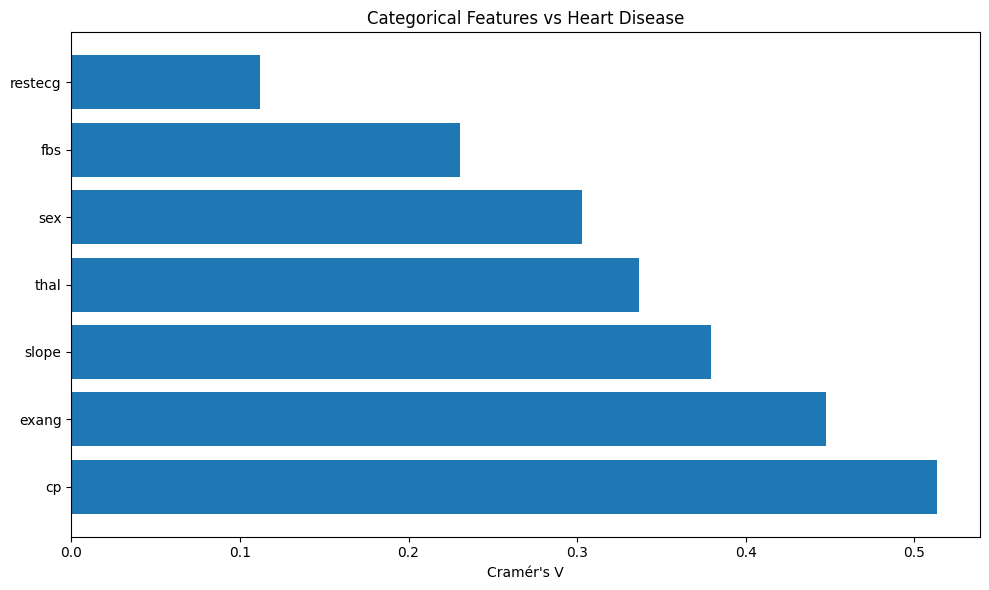

In [16]:
plt.figure(figsize=(10, 6))

plt.barh(
    categorical_target_df["Feature"],
    categorical_target_df["Cramers V"]
)

plt.xlabel("Cramér's V")
plt.title("Categorical Features vs Heart Disease")

plt.tight_layout()
plt.savefig("D:/1_Python Programmes/Projects/HDD/reports/categorical_target_association.png", dpi=300)
plt.show()